**Real-world question:** Can a small numerical model explain both the
long-term rise and the annual seasonal variation in the historical data?

**Deliverables:** coefficient table, comparison of two RMSE values,
observed-versus-fitted plot, residual plot, and a short critical conclusion.

We distinguish **exact systems** (`scipy.linalg.solve`) from **noisy,
overdetermined systems** (`scipy.linalg.lstsq`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when you launch Jupyter from the repository root or notebooks/ folder.
def data_path(filename):
    # Search for the data folder from the current
    # working directory up to the repository root.
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot find {filename}. "
        f"Current directory: {Path.cwd()}"
    )

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 105})

from scipy.linalg import solve, lstsq

In [2]:
df = (pd.read_csv(data_path('MaunaLoa_CO2_Full.csv'), parse_dates=['date'])
        .set_index('date').sort_index())
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == 2284, 'Please use the supplied full historical dataset.'
assert int(df['co2_ppm'].isna().sum()) == 59
print('Rows:', len(df), '| Missing:', df['co2_ppm'].isna().sum())
print('Period:', df.index.min().date(), 'to', df.index.max().date())
display(df.head())

Rows: 2284 | Missing: 59
Period: 1958-03-29 to 2001-12-29


,co2_ppm
date,
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


## Step 1 — Solve an exact three-equation calibration example
    For an illustrative quadratic `y = a + b·t + c·t²`, three independent
    equations can determine three coefficients. This is **not** evidence that
    a quadratic is a good model of the full environmental record.

In [3]:
A_exact = np.array([[1, 0, 0], [1, 1, 1], [1, 2, 4]], dtype=float)
b_exact = np.array([315, 318, 323], dtype=float)
coefficients_exact = solve(A_exact, b_exact)
print('Exact coefficients [a, b, c]:', coefficients_exact)
print('Residual norm:', np.linalg.norm(A_exact @ coefficients_exact - b_exact))
print('Matrix rank:', np.linalg.matrix_rank(A_exact),
      '| Condition number:', round(np.linalg.cond(A_exact), 2))

Exact coefficients [a, b, c]: [315.   2.   1.]
Residual norm: 0.0
Matrix rank: 3 | Condition number: 13.91


## Step 2 — Use **all original nonmissing readings** for least squares
    Unlike integration, least squares here does not require us to fill missing
    readings. We model the 2,225 **actually observed** values.

    Let `t` be elapsed years. The models are:

    - **Trend only:** `y = a + b·t`
    - **Trend + seasonality:** `y = a + b·t + c·sin(2πt) + d·cos(2πt)`

    Annual sine/cosine terms encode an approximately one-year cycle.

In [4]:
observed = df.dropna(subset=['co2_ppm']).copy()
t = (observed.index - observed.index[0]).days.to_numpy() / 365.2425
y = observed.co2_ppm.to_numpy()

A_trend = np.column_stack([np.ones_like(t), t])
A_seasonal = np.column_stack([
    np.ones_like(t), t, np.sin(2*np.pi*t), np.cos(2*np.pi*t)
])
coef_trend, *_ = lstsq(A_trend, y)
coef_seasonal, *_ = lstsq(A_seasonal, y)
fit_trend = A_trend @ coef_trend
fit_seasonal = A_seasonal @ coef_seasonal

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted)**2)))

results = pd.DataFrame({
    'model': ['Trend only', 'Trend + annual seasonality'],
    'parameters': [len(coef_trend), len(coef_seasonal)],
    'RMSE_ppm': [rmse(y, fit_trend), rmse(y, fit_seasonal)]
})
display(results.round(3))

,model,parameters,RMSE_ppm
0,Trend only,2,2.759
1,Trend + annual seasonality,4,1.918


## Step 3 — Interpret the model parameters
    The trend coefficient is in **ppm/year**. Seasonal amplitude is
    `sqrt(c² + d²)` in **ppm**. A good fit does not prove causation.

In [5]:
coefficient_table = pd.DataFrame({
    'term': ['intercept (ppm)', 'trend (ppm/year)', 'sin coefficient (ppm)',
             'cos coefficient (ppm)'],
    'estimate': coef_seasonal
})
display(coefficient_table.round(3))
print('Seasonal amplitude (ppm):', round(np.hypot(coef_seasonal[2],
                                                 coef_seasonal[3]), 3))

,term,estimate
0,intercept (ppm),310.204
1,trend (ppm/year),1.344
2,sin coefficient (ppm),1.200
3,cos coefficient (ppm),2.533


Seasonal amplitude (ppm): 2.803


## Step 4 — Inspect the fit and the residuals
    Residuals are `observed − predicted`. Systematic patterns indicate that
    the model may miss important structure even if RMSE looks reasonable.

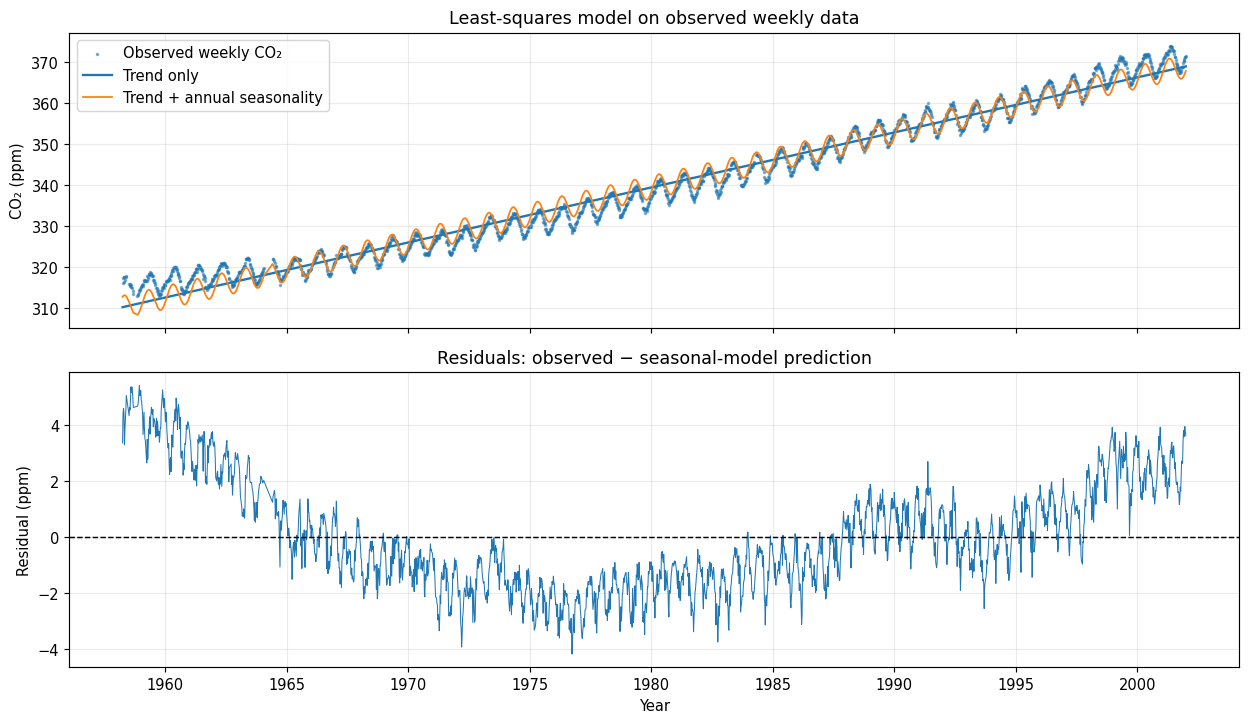

In [6]:
residuals = y - fit_seasonal
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].scatter(observed.index, y, s=2, alpha=0.5, label='Observed weekly CO₂')
axes[0].plot(observed.index, fit_trend, lw=1.6, label='Trend only')
axes[0].plot(observed.index, fit_seasonal, lw=1.2,
             label='Trend + annual seasonality')
axes[0].set(ylabel='CO₂ (ppm)', title='Least-squares model on observed weekly data')
axes[0].legend()
axes[1].plot(observed.index, residuals, lw=0.7)
axes[1].axhline(0, color='black', ls='--', lw=1)
axes[1].set(xlabel='Year', ylabel='Residual (ppm)',
            title='Residuals: observed − seasonal-model prediction')
plt.tight_layout()
plt.show()

## Step 5 — Check a **time-based** holdout
    Random train/test splitting can be misleading for a time series.
    Fit on readings through **1996**, then evaluate on **1997–2001**.
    The test period is later than the training period.

In [7]:
train_mask = observed.index.year <= 1996
test_mask = observed.index.year >= 1997
coef_train, *_ = lstsq(A_seasonal[train_mask], y[train_mask])
test_predictions = A_seasonal[test_mask] @ coef_train
print('Training readings:', train_mask.sum(),
      '| Later test readings:', test_mask.sum())
print('Training RMSE (ppm):',
      round(rmse(y[train_mask], A_seasonal[train_mask] @ coef_train), 3))
print('Later test RMSE (ppm):', round(rmse(y[test_mask], test_predictions), 3))

Training readings: 1964 | Later test readings: 261
Training RMSE (ppm): 1.75
Later test RMSE (ppm): 3.604


## Your investigation — compare, explain, critique
    **A.** How much does seasonal modelling reduce in-sample RMSE?

    **B.** What do the slope and seasonal amplitude mean in their own units?

    **C.** Does the later-period RMSE match the training RMSE? Why might
    historical nonlinearity make long-range predictions less reliable?

    **D.** Identify **one strength** and **one limitation** of this simple model.

    **Extension:** Add a quadratic trend term `t²` to the seasonal design matrix.
    Compare in-sample and later-period test errors. Does extra complexity help?

### YOUR TURN
 1. Add t**2 to the design matrix.
 2. Fit using scipy.linalg.lstsq.
 3. Compare training and later test RMSE with the simpler seasonal model.
 4. Describe any trade-off between flexibility and generalisation.

### Reflection checklist
    - [ ] I used `solve` for the exact system and `lstsq` for noisy data.
    - [ ] I kept the original missing values out of the regression.
    - [ ] I interpreted trend in **ppm/year** and seasonal amplitude in **ppm**.
    - [ ] I inspected residuals and evaluated on a later period.